__SVM__

In [26]:
# Подключение библиотек
import matplotlib.pyplot as plt
from matplotlib import gridspec 
import seaborn as sns 
import pandas as pd 
from tqdm.notebook import tqdm
from scipy.special import softmax 
from scipy.spatial.distance import cdist 
import numpy as np 
import torch
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC, SVR
from sklearn.metrics import classification_report
from sklearn.model_selection import KFold, ParameterGrid
from sklearn.datasets import make_classification, make_regression
from sklearn.model_selection import train_test_split
from mlxtend.plotting import plot_decision_regions

In [27]:
#Генерируем выборку
X, Y = make_classification(n_samples=150, n_features=2, 
                           n_informative=2, n_classes=2, 
                           n_redundant=0, 
                           n_clusters_per_class=1, 
                           random_state=40)
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=50, random_state=0)

In [28]:
for k in np.unique(Y):
    pit.plot(X[Y==k, 0], X[Y==k, 1], 'o')
plt.show()    

NameError: name 'pit' is not defined

In [ ]:
#Обучаем линейную модель
model = SVC(kernel='linear')
_ = model.fit (X_train, Y_train)

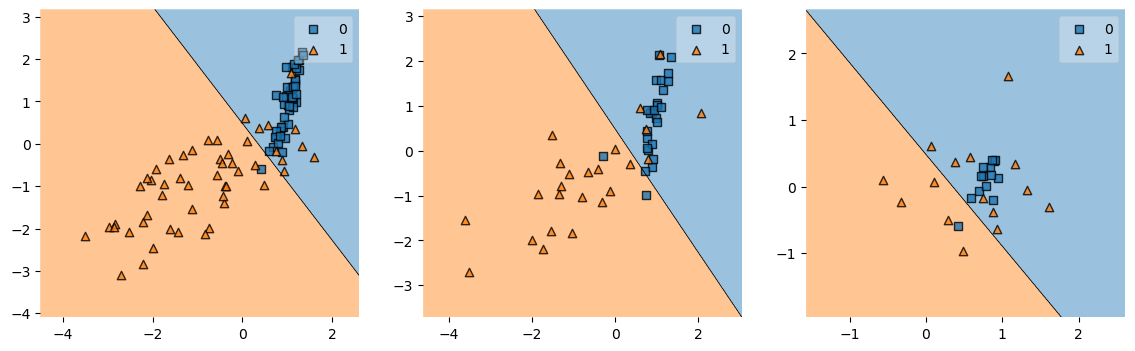

In [ ]:
#Графически отображаем результаты
fig, gs = pit.figure(figsize=(14,4)), gridspec.GridSpec(1, 3)
ax = []
for i in range(3):
    ax.append(fig.add_subplot(gs[i]))
plot_decision_regions(X_train, Y_train, model, ax=ax[0]) 
plot_decision_regions(X_test, Y_test, model, ax=ax[1])
plot_decision_regions(X_train[model.support_], Y_train[model.support_], model, ax=ax[2])

plt.show()

__Раздичные ядра для SVM__

In [ ]:
# Геренация новой выборки
np.random.seed(0)
m = 150 
n = 2
X = 10*np.random.randn(m, n)
Y = np.array((X[:,0]**2+X[:,1]**2+50*np.random.randn(m))<100, dtype=np.int64)
X_train, X_test, Y_train, Ytest = train_test_split(X, Y, test_size=50, random_state=0)

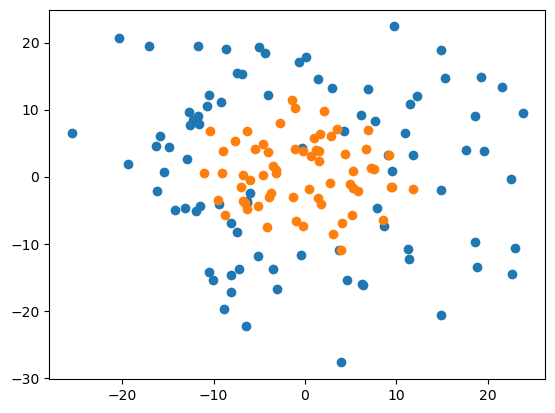

In [ ]:
for k in np.unique(Y):
    pit.plot(X[Y==k, 0], X[Y==k, 1], 'o')
plt.show()    

In [ ]:
#Обучение полиномиальной модели

model = SVC(kernel='poly')
_ = model.fit (X_train, Y_train)

#сигмоидная модель  model = SVC(kernel='sigmoid')

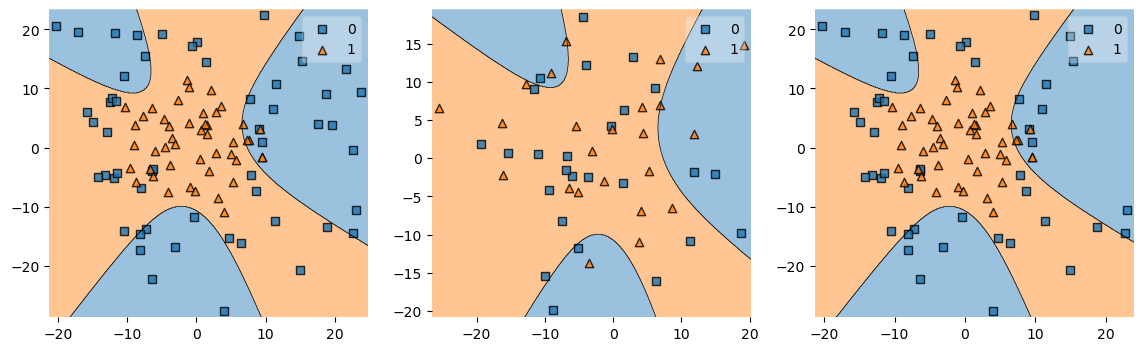

In [ ]:
#Построение
fig, gs = pit.figure(figsize=(14,4)), gridspec.GridSpec(1, 3)
ax = []
for i in range(3):
    ax.append(fig.add_subplot(gs[i]))
plot_decision_regions(X_train, Y_train, model, ax=ax[0]) 
plot_decision_regions(X_test, Y_test, model, ax=ax[1])
plot_decision_regions(X_train[model.support_], Y_train[model.support_], model, ax=ax[2])

plt.show()

__Гауссово ядро с радиальной базовой функцией (RBF):  $ K(x_i,x_j)=exp(γ||x_i−x_j||^2)$__


In [ ]:
#Обучаем линейную модель
model = SVC(kernel='rbf')
_ = model.fit (X_train, Y_train)

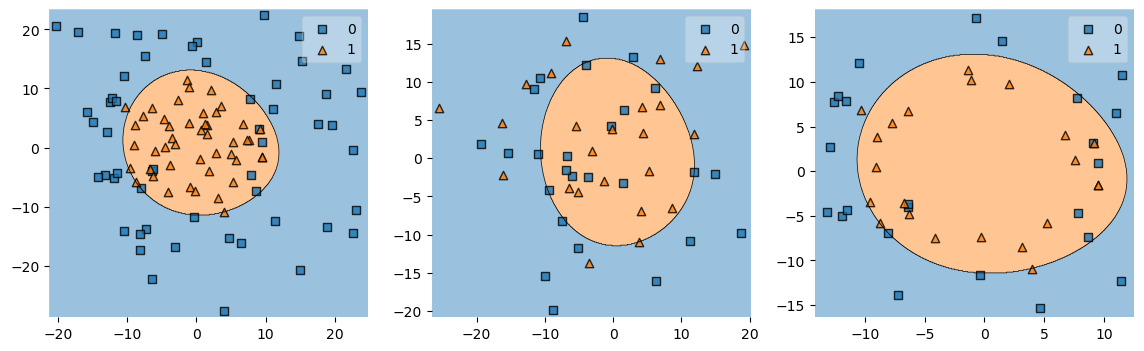

In [ ]:
#Построение
fig, gs = pit.figure(figsize=(14,4)), gridspec.GridSpec(1, 3)
ax = []
for i in range(3):
    ax.append(fig.add_subplot(gs[i]))
plot_decision_regions(X_train, Y_train, model, ax=ax[0]) 
plot_decision_regions(X_test, Y_test, model, ax=ax[1])
plot_decision_regions(X_train[model.support_], Y_train[model.support_], model, ax=ax[2])

plt.show()

__SVM Regression__

In [ ]:
np.random.seed(0)
l = 150
# Генерация данных
x = np.linspace(0, 30, num=l)
Y_without_noise = x + 4*np.sin(x)
Y = Y_without_noise + 4*np.random.randn(l)
# Генерация признаков. Два признака х - линейные и np.sin(x) - через синус. 
X = np.array([x, np.sin(x)]).T
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=50, random_state=0)


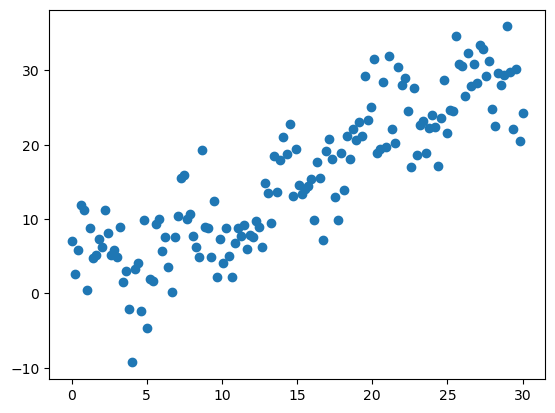

In [ ]:
plt.plot(X[:, 0], Y, 'o')
plt.show()

In [ ]:
#Ядро RBF
model = SVR(kernel='rbf')
_ = model.fit(X_train, Y_train)

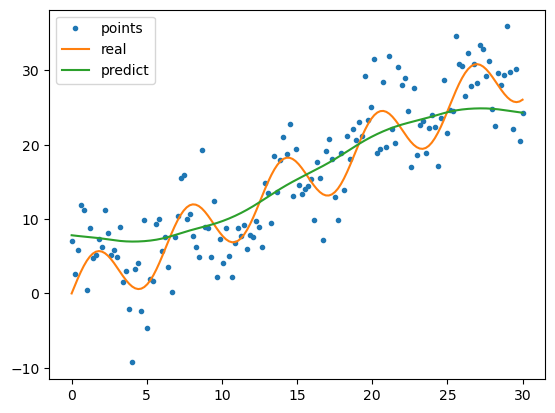

In [ ]:
plt.plot(x, Y,'.', label='points')
plt.plot(x, Y_without_noise, label='real') 
plt.plot(x, model.predict(X), label='predict')
pit.legend(loc='best') 
pit.show()

In [ ]:
#Ядро линейное
model = SVR(kernel='linear')
_ = model.fit(X_train, Y_train)

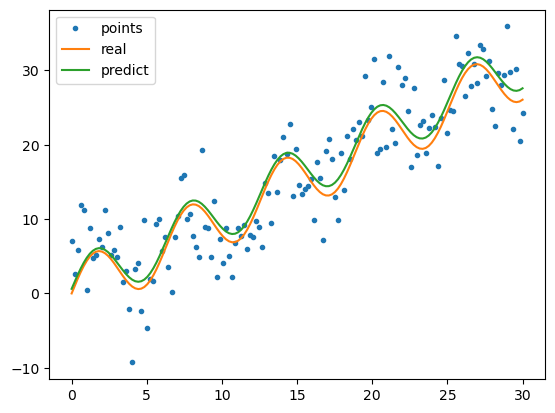

In [ ]:
plt.plot(x, Y,'.', label='points')
plt.plot(x, Y_without_noise, label='real') 
plt.plot(x, model.predict(X), label='predict')
pit.legend(loc='best') 
pit.show()

In [ ]:
np.random.seed(0)
l = 150
# Генерация данных
x = np.linspace(0, 30, num=l)
Y_without_noise = x + 4*np.sin(x)
Y = Y_without_noise + 4*np.random.randn(l)
# Генерация признаков
X = np.array( [x]).T
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=50, random_state=0)


In [ ]:
# Организация собственного ядра. Это то-же самое, что и X = np.array([x, np.sin(x)]).T используемое ранее.
def kernel(X1, X2):
    return np.sin(X1)@np.sin(X2).T + X1@X2.T

In [ ]:
#Ядро линейное
model = SVR(kernel=kernel)
_ = model.fit(X_train, Y_train)

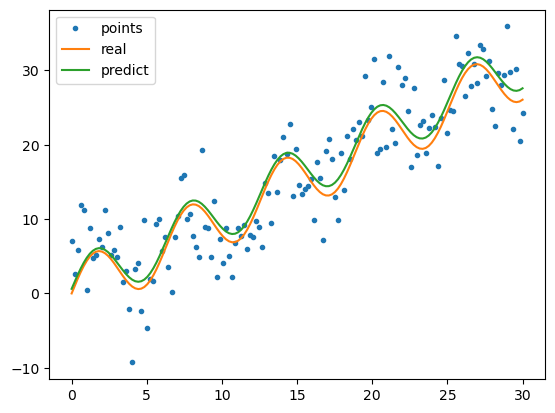

In [ ]:
plt.plot(x, Y,'.', label='points')
plt.plot(x, Y_without_noise, label='real') 
plt.plot(x, model.predict(X), label='predict')
pit.legend(loc='best') 
pit.show()

__SVM Продолжение__

In [ ]:
X, Y = make_classification(n_samples=2500, n_features=10, 
                           n_informative=2, n_classes=2, 
                           n_redundant=0, n_clusters_per_class=1, 
                           random_state=10)

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, 
                                                    test_size=500, 
                                                    random_state=0)

In [ ]:
# RBF ядро
def kernel(X1, X2):
    return np.exp(-0.05*cdist(X1, X2)**2)

In [ ]:
model = SVC(kernel=kernel)
_ = model.fit(X_train, Y_train) 
print('Accuracy =', model.score(X_test, Y_test))

Accuracy = 0.916


__Нормализация__

In [ ]:
scaler = StandardScaler() 
scaler.fit(X_train)
X_train = scaler.transform(X_train) 
X_test = scaler.transform(X_test)

In [ ]:
model = SVC(kernel=kernel)
_ = model.fit(X_train, Y_train) 
print('Accuracy =', model.score(X_test, Y_test))

Accuracy = 0.912


____Задание____ 

1. Классификация
Датасет сформирован следующей командой:
X, Y = make_classification(n_samples=100, n_features=2, n_informative=2, n_redundant=0, n_clusters_per_class=2)
Подобрать тип ядра и гиперпараметры для данной выборки. Произвести визуальное сравнение разных ядер и разных гиперпараметров. Сравнить точность для разных случаев.

2. Регрессия
Использовать датасет по гиперспектру кукурузы. 
Подобрать тип ядра и гиперпараметры для данной выборки. Произвести визуальное сравнение разных ядер и разных гиперпараметров. Сравнить точность для разных случаев.

3. Использовать любой из датасетов и любых два метода классификации или регрессии, изученные на предыдущих занятиях. Произвести сравнение 
работы этих методов и метода SVM. Кроме точности использовать и другие метрики качества алгоритма.

In [29]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib import gridspec
from sklearn.datasets import make_classification
from sklearn.svm import SVC, SVR
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (classification_report, accuracy_score, roc_auc_score,
                             mean_squared_error, mean_absolute_error, r2_score)
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor, GradientBoostingRegressor
from sklearn.linear_model import LogisticRegression
from mlxtend.plotting import plot_decision_regions

In [30]:
X, y = make_classification(n_samples=100, n_features=2, n_informative=2, n_redundant=0, n_clusters_per_class=2)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(X_scaled, y, test_size=0.33, random_state=0, stratify=y)

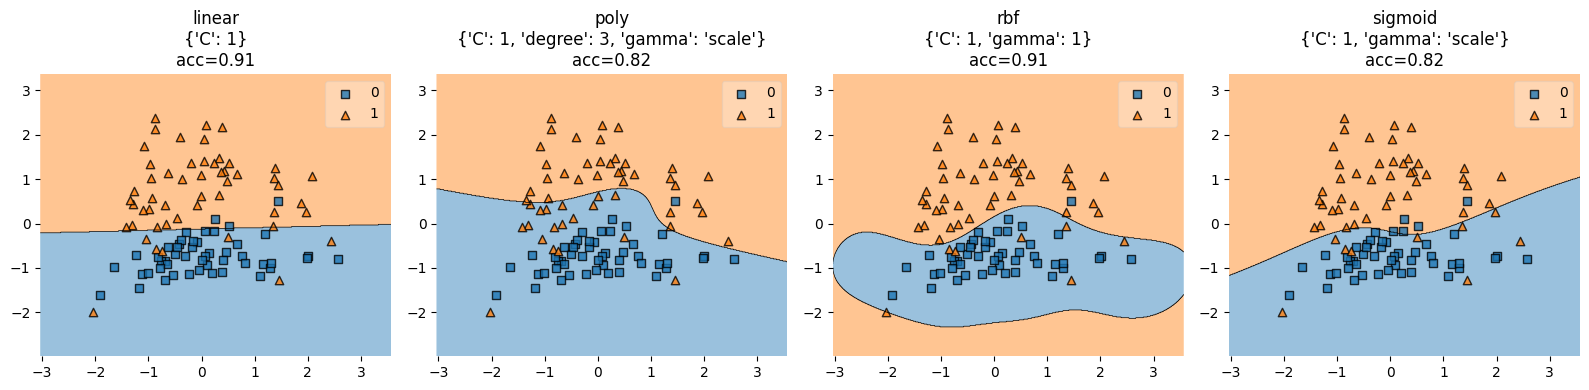

In [32]:
kernels = ['linear', 'poly', 'rbf', 'sigmoid']
results = []

fig = plt.figure(figsize=(16, 4))
gs = gridspec.GridSpec(1, len(kernels))

for i, kernel in enumerate(kernels):
    if kernel == 'linear':
        param_grid = {'C': [0.1, 1, 10]}
    elif kernel == 'rbf' or kernel == 'sigmoid':
        param_grid = {'C': [0.1, 1, 10], 'gamma': ['scale', 'auto', 0.1, 1]}
    elif kernel == 'poly':
        param_grid = {'C': [0.1, 1, 10], 'gamma': ['scale', 'auto'], 'degree': [2, 3, 4]}
    
    gs_clf = GridSearchCV(SVC(kernel=kernel), param_grid, cv=4, scoring='accuracy', n_jobs=-1)
    gs_clf.fit(X_train_c, y_train_c)
    
    best = gs_clf.best_estimator_
    y_pred = best.predict(X_test_c)
    acc = accuracy_score(y_test_c, y_pred)
    
    results.append((kernel, gs_clf.best_params_, acc))
    
    ax = fig.add_subplot(gs[i])
    plot_decision_regions(np.vstack([X_train_c, X_test_c]),
                          np.hstack([y_train_c, y_test_c]),
                          clf=best, ax=ax)
    ax.set_title(f"{kernel}\n{gs_clf.best_params_}\nacc={acc:.2f}")

plt.tight_layout()
plt.show()

In [ ]:
for r in results:
    print(r)

Результаты классификации (ядра):
('linear', {'C': 1}, 0.9090909090909091)
('poly', {'C': 1, 'degree': 3, 'gamma': 'scale'}, 0.8181818181818182)
('rbf', {'C': 1, 'gamma': 1}, 0.9090909090909091)
('sigmoid', {'C': 1, 'gamma': 'scale'}, 0.8181818181818182)


In [34]:
gipers = pd.read_csv(r"Гиперспектр кукурузы.csv")
X, y = gipers["wavelength"], gipers["Spectr"]
X, y = X.to_numpy().reshape(-1, 1), y.to_numpy().reshape(-1, 1)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_train, X_val, y_train, y_val = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42
)

In [35]:
param_grid = [
    {'kernel': ['rbf'], 'C': [1, 10, 100], 'gamma': ['scale', 0.01, 0.1]},
    {'kernel': ['linear'], 'C': [1, 10, 100]},
    {'kernel': ['poly'], 'C': [1, 10], 'degree': [2, 3], 'gamma': ['scale']}
]

svr = SVR()
gs_reg = GridSearchCV(svr, param_grid, scoring='neg_mean_squared_error', cv=4, n_jobs=-1)
gs_reg.fit(X_train, y_train)

print("Лучшие параметры SVR:", gs_reg.best_params_)

Лучшие параметры SVR: {'C': 100, 'gamma': 'scale', 'kernel': 'rbf'}


c:\Users\NKTKLN\Desktop\MIREA\AI\.venv\Lib\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


In [36]:
best_svr = gs_reg.best_estimator_
y_pred_te = best_svr.predict(X_val)

rmse = np.sqrt(mean_squared_error(y_val, y_pred_te))
mae = mean_absolute_error(y_val, y_pred_te)
r2 = r2_score(y_val, y_pred_te)

print(f"Тест (SVR): RMSE={rmse:.3f}, MAE={mae:.3f}, R2={r2:.3f}")

Тест (SVR): RMSE=0.062, MAE=0.055, R2=0.861


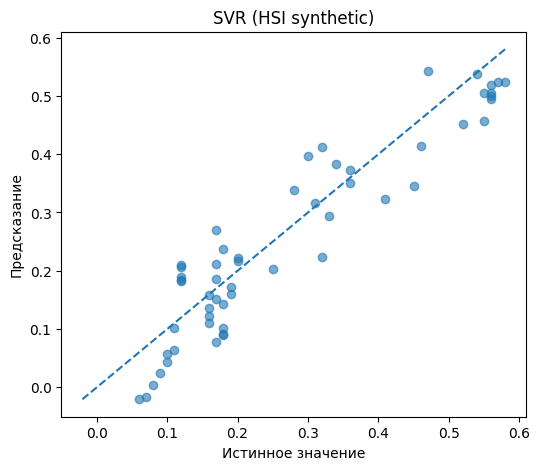

In [37]:
plt.figure(figsize=(6,5))
plt.scatter(y_val, y_pred_te, alpha=0.6)
mn, mx = min(y_val.min(), y_pred_te.min()), max(y_val.max(), y_pred_te.max())
plt.plot([mn,mx],[mn,mx],'--')
plt.xlabel("Истинное значение")
plt.ylabel("Предсказание")
plt.title("SVR (HSI synthetic)")
plt.show()

In [ ]:
models_class = {
    'SVC_rbf': SVC(kernel='rbf', C=1, gamma='scale', probability=True),
    'Logistic': LogisticRegression(max_iter=200),
    'RandomForest': RandomForestClassifier(n_estimators=200, random_state=0)
}

for name, mdl in models_class.items():
    mdl.fit(X_train_c, y_train_c)
    y_pred = mdl.predict(X_test_c)
    acc = accuracy_score(y_test_c, y_pred)
    if hasattr(mdl, "predict_proba"):
        probs = mdl.predict_proba(X_test_c)[:,1]
        auc = roc_auc_score(y_test_c, probs)
    else:
        auc = np.nan
    print(f"{name}: accuracy={acc:.3f}, ROC-AUC={auc}")

Сравнение классификаторов:
SVC_rbf: accuracy=0.909, ROC-AUC=0.9669117647058824
Logistic: accuracy=0.879, ROC-AUC=0.9632352941176471
RandomForest: accuracy=0.939, ROC-AUC=0.9632352941176471


In [ ]:
models_reg = {
    'SVR_best': best_svr,
    'RandomForestReg': RandomForestRegressor(n_estimators=200, random_state=0),
    'GradientBoosting': GradientBoostingRegressor(n_estimators=200, random_state=0)
}

for name, mdl in models_reg.items():
    mdl.fit(X_train, y_train)
    y_pred = mdl.predict(X_val)
    rmse = np.sqrt(mean_squared_error(y_val, y_pred))
    mae = mean_absolute_error(y_val, y_pred)
    r2 = r2_score(y_val, y_pred)
    print(f"{name}: RMSE={rmse:.3f}, MAE={mae:.3f}, R2={r2:.3f}")

Сравнение регрессоров:
SVR_best: RMSE=0.062, MAE=0.055, R2=0.861


c:\Users\NKTKLN\Desktop\MIREA\AI\.venv\Lib\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
c:\Users\NKTKLN\Desktop\MIREA\AI\.venv\Lib\site-packages\sklearn\base.py:1365: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


RandomForestReg: RMSE=0.012, MAE=0.008, R2=0.994
GradientBoosting: RMSE=0.015, MAE=0.010, R2=0.991


c:\Users\NKTKLN\Desktop\MIREA\AI\.venv\Lib\site-packages\sklearn\ensemble\_gb.py:672: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)  # TODO: Is this still required?


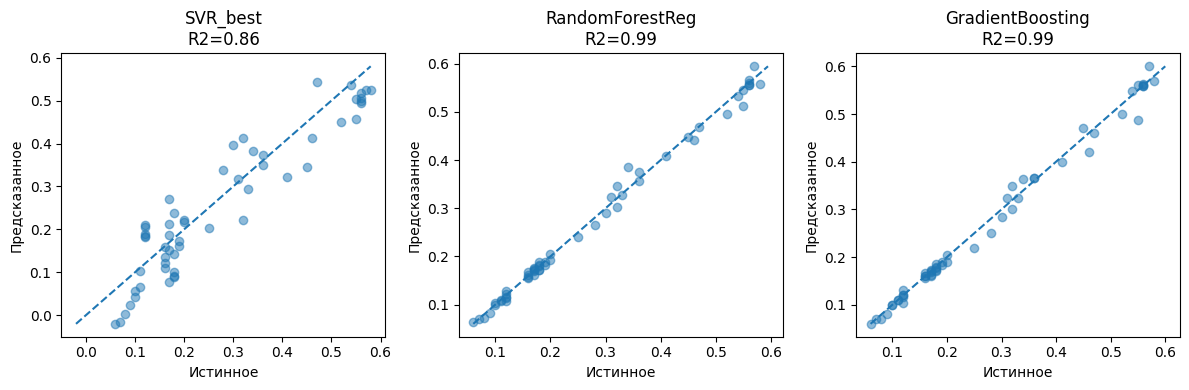

In [42]:
plt.figure(figsize=(12,4))
for i,(name, mdl) in enumerate(models_reg.items()):
    y_pred = mdl.predict(X_val)
    plt.subplot(1, 3, i+1)
    plt.scatter(y_val, y_pred, alpha=0.5)
    mn, mx = min(y_val.min(), y_pred.min()), max(y_val.max(), y_pred.max())
    plt.plot([mn,mx],[mn,mx],'--')
    plt.title(f"{name}\nR2={r2_score(y_val,y_pred):.2f}")
    plt.xlabel("Истинное")
    plt.ylabel("Предсказанное")
plt.tight_layout()
plt.show()